<a href="https://colab.research.google.com/github/Gaurav1764/Gen-AI-Lab2/blob/main/Lab2_GAN_Image_Synthesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K.R. Mangalam University | MCA | ETMMGA304 Generative AI and Its Applications
## Lab 2: Image Synthesis Using GANs
**Bloom's level:** BTX 3 Apply, BTX 4 Analyze, BTX 5 Evaluate

| Lab record field | Entry |
|---|---|
| Student name / roll no. | Gaurav Kumar (2501940033) |
| Experiment title | Lab 2: Image Synthesis Using GANs |
| Date | 22/11/2026 |
| Aim | Train a basic GAN on Fashion-MNIST; inspect fixed inputs across epochs and use images alongside losses to evaluate training. |
| Software used | Python, PyTorch, torchvision, Matplotlib (Google Colab) |
| Dataset / model identifier | Fashion-MNIST (torchvision.datasets.FashionMNIST) |
| Parameters | latent dim 64, batch 128, Adam lr 0.0002 betas (0.5, 0.999), BCEWithLogits, 10 epochs |
| Seed | 42 |

> Run the **Common Setup** cell first, then every cell in order. Keep your *own* losses, samples and screenshots. Download this notebook and the files in `lab_outputs` before the session ends.

## Common Setup

In [1]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

Device: cuda


In [2]:
# Lab record: environment details (copy these into your record)
import sys, platform, datetime
print("Date        :", datetime.date.today())
print("Python      :", sys.version.split()[0], "|", platform.platform())
print("PyTorch     :", torch.__version__)
print("Device      :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("Seed        :", SEED)

Date        : 2026-11-23
Python      : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch     : 2.14.1+cu130
Device      : cuda | Tesla T4
Seed        : 42


## How it works
The **generator** maps a random vector to an image. The **discriminator** outputs a real/fake logit. In the discriminator update it sees real samples and **detached** generator outputs. In the generator update, gradients pass through the discriminator into the generator while the discriminator's weights stay fixed.

`Noise -> Generator -> Synthetic image -> Discriminator -> Real or fake score`

## Step 1: Load and scale images
Real pixels are normalised to about [-1, 1] to match the generator's `tanh` output range.

In [3]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))
])
data = datasets.FashionMNIST("data", train=True, download=True,
                             transform=transform)
loader = DataLoader(data, batch_size=128, shuffle=True)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.4MB/s]


## Step 2: Define both networks

In [4]:
latent_dim = 64
G = nn.Sequential(nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2),
                  nn.Linear(256, 512), nn.LeakyReLU(0.2),
                  nn.Linear(512, 784), nn.Tanh()).to(device)
D = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
                  nn.Linear(512, 256), nn.LeakyReLU(0.2),
                  nn.Linear(256, 1)).to(device)
loss_fn = nn.BCEWithLogitsLoss()
opt_g = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))
fixed_z = torch.randn(25, latent_dim, device=device)

### Checks before the training loop
* Real-image normalisation matches the generator output range.
* Shapes: noise `N x 64`; generator output `N x 784` in [-1, 1]; discriminator output `N x 1` logits.
* The *same* `fixed_z` is used for every saved grid.

In [5]:
z = torch.randn(4, latent_dim, device=device)
with torch.no_grad():
    g = G(z); d = D(g)
print("Noise batch        :", tuple(z.shape))
print("Generator output   :", tuple(g.shape), "range", round(g.min().item(), 3), "to", round(g.max().item(), 3))
print("Discriminator out  :", tuple(d.shape))
assert z.shape == (4, 64) and g.shape == (4, 784) and d.shape == (4, 1)
assert g.min() >= -1 and g.max() <= 1
xb, _ = next(iter(loader))
print("Real pixel range   :", round(xb.min().item(), 3), "to", round(xb.max().item(), 3))
assert xb.min() >= -1.0001 and xb.max() <= 1.0001
print("All checks passed: real data and generator share the [-1, 1] range.")

Noise batch        : (4, 64)
Generator output   : (4, 784) range -0.389 to 0.348
Discriminator out  : (4, 1)
Real pixel range   : -1.0 to 1.0
All checks passed: real data and generator share the [-1, 1] range.


## Step 3: Implement alternating updates

In [6]:
def generate_grid(epoch):
    with torch.no_grad():
        images = G(fixed_z).cpu().reshape(-1, 1, 28, 28)
    grid = make_grid((images + 1) / 2, nrow=5)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(f"Epoch {epoch}")
    plt.axis("off")
    plt.savefig(out / f"gan_epoch_{epoch:02d}.png", bbox_inches="tight")
    plt.show()

def train_batch(real):
    n = real.size(0)
    fake = G(torch.randn(n, latent_dim, device=device))
    real_logits = D(real)
    fake_logits = D(fake.detach())          # detach: no gradient into G during the D step
    d_loss = (loss_fn(real_logits, torch.ones_like(real_logits))
              + loss_fn(fake_logits, torch.zeros_like(fake_logits))) / 2
    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()

    D.requires_grad_(False)                 # D weights fixed for the G update
    opt_g.zero_grad()
    logits = D(fake)
    g_loss = loss_fn(logits, torch.ones_like(logits))
    g_loss.backward()
    opt_g.step()
    D.requires_grad_(True)
    return d_loss.item(), g_loss.item()

## Step 4: Train and compare epochs
Saves grids at epochs 1, 5 and 10, the loss plot and the generator checkpoint. A simple diversity number (mean pairwise distance between the 25 fixed samples) is logged as *supporting* evidence; always judge diversity visually too.

01 D=0.355 G=1.831  diversity=15.33


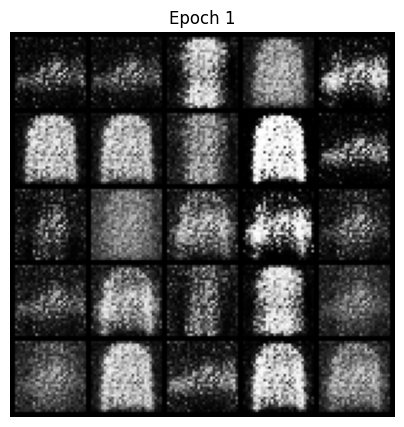

02 D=0.327 G=2.635  diversity=18.74
03 D=0.369 G=2.380  diversity=19.16
04 D=0.416 G=2.001  diversity=20.03
05 D=0.411 G=2.026  diversity=20.53


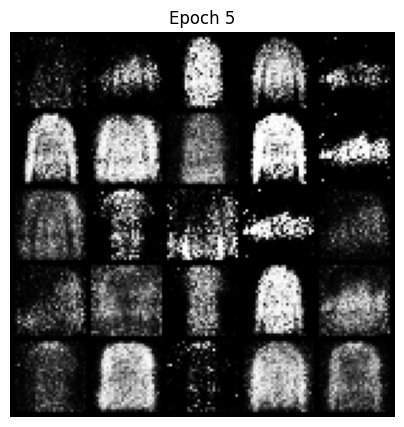

06 D=0.439 G=1.875  diversity=20.99
07 D=0.448 G=1.847  diversity=20.95
08 D=0.458 G=1.808  diversity=21.24
09 D=0.462 G=1.785  diversity=21.70
10 D=0.465 G=1.701  diversity=21.83


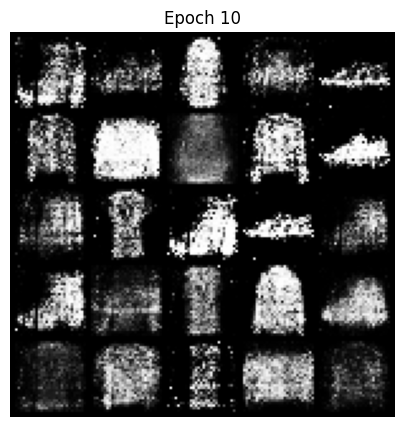

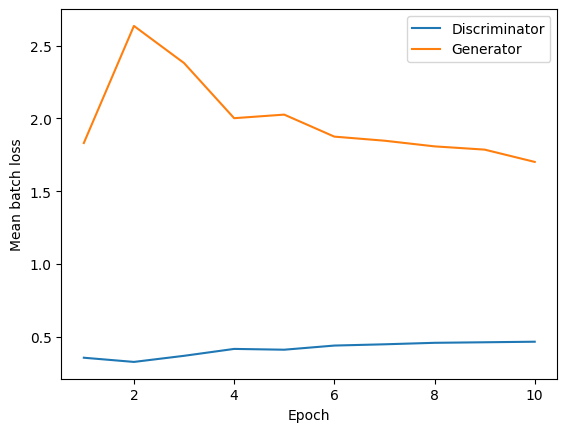

In [7]:
import pandas as pd

def diversity():
    with torch.no_grad():
        f = G(fixed_z).flatten(1)
    return torch.pdist(f).mean().item()

history = []
for epoch in range(1, 11):
    losses = [train_batch(real.to(device)) for real, _ in loader]
    avg_d, avg_g = [sum(values) / len(losses) for values in zip(*losses)]
    history.append((avg_d, avg_g))
    print(f"{epoch:02d} D={avg_d:.3f} G={avg_g:.3f}  diversity={diversity():.2f}")
    if epoch in (1, 5, 10):
        generate_grid(epoch)

plt.plot(range(1, 11), [d for d, g in history], label="Discriminator")
plt.plot(range(1, 11), [g for d, g in history], label="Generator")
plt.xlabel("Epoch")
plt.ylabel("Mean batch loss")
plt.legend()
plt.savefig(out / "gan_losses.png", bbox_inches="tight")
plt.show()
torch.save(G.state_dict(), out / "fashion_generator.pt")

### Observation table (epochs 1, 5, 10)
D and G loss are filled from your run. Fill the last two columns by comparing the **same grid positions** across `gan_epoch_01/05/10.png`.

In [8]:
rows = []
for e in (1, 5, 10):
    d_l, g_l = history[e - 1]
    rows.append({"Epoch": e, "D loss": round(d_l, 3), "G loss": round(g_l, 3),
                 "Recognizable out of 25": None, "Repeated shapes or artifacts": ""})
obs = pd.DataFrame(rows)
obs.to_csv(out / "gan_observation_table.csv", index=False)
pd.DataFrame(history, columns=["D loss", "G loss"]).rename_axis("epoch0").to_csv(out / "gan_loss_history.csv")
display(obs)
print("Files saved:", sorted(p.name for p in out.iterdir()))

,Epoch,D loss,G loss,Recognizable out of 25,Repeated shapes or artifacts
0,1,0.355,1.831,None,
1,5,0.411,2.026,None,
2,10,0.465,1.701,None,


Files saved: ['fashion_generator.pt', 'gan_epoch_01.png', 'gan_epoch_05.png', 'gan_epoch_10.png', 'gan_loss_history.csv', 'gan_losses.png', 'gan_observation_table.csv']


## Your observations
| Epoch | D loss | G loss | Recognizable out of 25 | Repeated shapes or artifacts |
|---|---|---|---|---|
| 1 | | | | |
| 5 | | | | |
| 10 | | | | |

* Result (2-3 sentences, using **both grids and losses**): ...
* Do repeated silhouettes appear across many grid positions (possible reduced diversity)? ...
* One failure / limitation: ...  One next step: ...

## Submission
Three sample grids (`gan_epoch_01.png`, `gan_epoch_05.png`, `gan_epoch_10.png`), the loss plot (`gan_losses.png`) and the completed table.

## Viva questions: draft answers
1. **What does each network learn?** The generator learns to map noise to images that the discriminator scores as real; the discriminator learns to separate real images from generated ones.
2. **Why detach the generated batch in the discriminator step?** So the discriminator loss does not send gradients back into the generator; only the discriminator's weights should change in that step.
3. **Why keep the grid inputs fixed?** The same noise vectors let you compare how *the same grid position* changes across epochs, so differences come from training rather than different inputs.
4. **How can a grid reveal mode collapse?** If many positions show the same or near-identical silhouette (e.g. the same shoe or shirt), the generator is covering only a few modes of the data.

In [ ]:
# Download everything for submission (works in Colab; elsewhere files stay in lab_outputs/)
import shutil
shutil.make_archive("lab_outputs_submission", "zip", "lab_outputs")
try:
    from google.colab import files
    files.download("lab_outputs_submission.zip")
except ImportError:
    print("Not in Colab. Collect the zip: lab_outputs_submission.zip")